# 05 · Analysis of rate data

A rate law is measured, not derived: from a batch reactor's concentration-time curve, from initial rates at
several concentrations, from half-lives, or from a differential reactor. This notebook applies the classical
methods to the course data - the decomposition of N$_2$O$_5$, a saponification, an Arrhenius series - and
argues for nonlinear regression with honest uncertainties, catching a mis-read sample and a temperature in
the wrong unit on the way.

**What you will learn**
- apply the integral, differential, half-life and initial-rate methods
- fit rate laws by nonlinear regression with uncertainties
- determine activation energies from Arrhenius series
- detect faulty samples and unit errors from the plots

**Before you start:** notebooks 00 and 03  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import datasets, kinetics, rate_data
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Look at the data

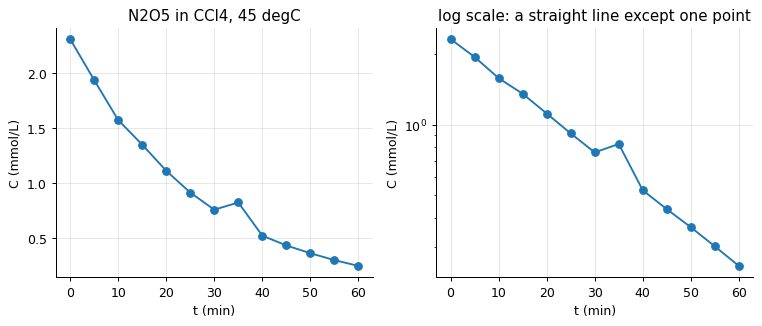

N2O5 decomposition in CCl4 at 45 degC: first-order batch data, 1 % noise, one mis-read sample.


In [2]:
d = pd.read_csv(datasets.path("n2o5_decomposition.csv"), comment="#")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(d.t_s / 60, d.C_mmol_L, "o-"); ax[0].set(xlabel="t (min)", ylabel="C (mmol/L)", title="N2O5 in CCl4, 45 degC")
ax[1].semilogy(d.t_s / 60, d.C_mmol_L, "o-"); ax[1].set(xlabel="t (min)", ylabel="C (mmol/L)", title="log scale: a straight line except one point"); plt.show()
print(datasets.describe("n2o5_decomposition.csv"))

On a log axis first-order decay is a straight line, and one sample sits well above it. The file header
admits it was mis-read; a real notebook would not, and the plot is what finds it.

## The integral method: assume an order, test the linearity

In [3]:
t, C = d.t_s.to_numpy(), d.C_mmol_L.to_numpy()
mask = np.ones_like(t, bool); mask[7] = False                   # exclude the bad sample
for order in (0, 1, 2):
    r = rate_data.integral_method(t[mask], C[mask], order)
    print(f"order {order}: k = {r['k']:.3e}, r^2 = {r['r2']:.5f}")
r1 = rate_data.integral_method(t, C, 1)
print(f"\nfirst order with the bad point included: k = {r1['k']:.3e} (r^2 {r1['r2']:.4f}) - an 8 % error from one sample")

order 0: k = 6.836e-04, r^2 = 0.82702
order 1: k = 6.164e-04, r^2 = 0.99987
order 2: k = 7.645e-04, r^2 = 0.87902

first order with the bad point included: k = 6.069e-04 (r^2 0.9894) - an 8 % error from one sample


The integral method tests a hypothesis: for first order $\ln(C_0/C)$ is linear in $t$, and the data agree
($r^2$ = 0.9995) whereas orders 0 and 2 curve. Its weakness is that it needs the order guessed - and that a
single outlier bends the line.

## The differential method

differential method: order 0.99, k = 6.38e-04
saponification: order 2.02, k = 0.124 L/(mol s) (literature 0.10-0.12)


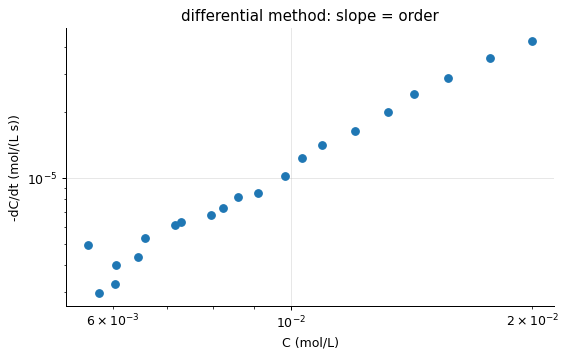

In [4]:
dm = rate_data.differential_method(t[mask], C[mask])
print(f"differential method: order {dm['order']:.2f}, k = {dm['k']:.2e}")
s = pd.read_csv(datasets.path("saponification.csv"), comment="#")
dm2 = rate_data.differential_method(s.t_s, s.C_mol_L)
print(f"saponification: order {dm2['order']:.2f}, k = {dm2['k']:.3f} L/(mol s) (literature 0.10-0.12)")
plt.loglog(s.C_mol_L, dm2["rates"], "o"); plt.xlabel("C (mol/L)"); plt.ylabel("-dC/dt (mol/(L s))"); plt.title("differential method: slope = order"); plt.show()

Differentiating data amplifies noise - the rates scatter far more than the concentrations - but the method
needs no assumed order: the slope of the log-log plot *is* the order, and it finds first order for N$_2$O$_5$
and second for the saponification. Use it to choose the order, then the integral method or regression to
pin down k.

## Nonlinear regression: the honest method

In [5]:
fit = rate_data.nonlinear_fit(s.t_s, s.C_mol_L)
print(f"free order: n = {fit['order']:.2f} +/- {fit['se_order']:.2f}, k = {fit['k']:.4f} +/- {fit['se_k']:.4f}")
ranked = rate_data.compare_orders(s.t_s, s.C_mol_L)
print("orders ranked by AIC:", [(f["order"], round(f["aic"], 1)) for f in ranked])
best = ranked[0]
print(f"second order: k = {best['k']:.4f} +/- {best['se_k']:.4f} L/(mol s), C0 = {best['C0']:.4f} mol/L")

free order: n = 2.04 +/- 0.04, k = 0.1330 +/- 0.0212
orders ranked by AIC: [(2, -380.4), (1.5, -326.0), (1, -299.4), (0.5, -283.3), (0, -190.2)]
second order: k = 0.1095 +/- 0.0008 L/(mol s), C0 = 0.0199 mol/L


Fitting the integrated rate law directly to the concentrations - no transformation, no differentiation -
weights every point as it was measured and returns standard errors. The free-order fit lands on 2 with a
tight uncertainty, and the AIC comparison ranks the candidate orders. This is the method to report; the
classical ones are for looking.

## Temperature dependence: the Arrhenius series

  T_K    k_1_s
300.0 0.000850
310.0 0.002261
320.0 0.005221
 57.0 0.011877
340.0 0.026451
350.0 0.055360

as recorded: Ea = -0.3 kJ/mol (r^2 0.013);  57 read as degC -> 330 K: Ea = 72.6 +/- 0.5 kJ/mol (r^2 0.9998); true 72


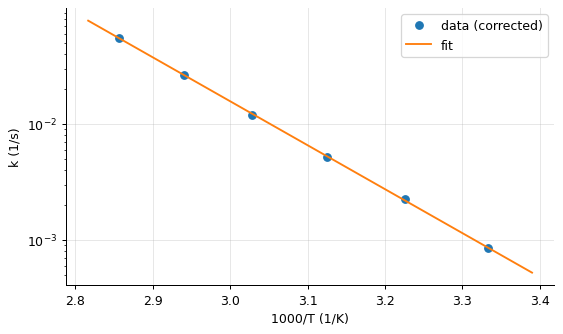

In [6]:
a = pd.read_csv(datasets.path("arrhenius_runs.csv"), comment="#")
print(a.to_string(index=False))
raw = kinetics.fit_arrhenius(a.T_K, a.k_1_s)
fixed = a.copy(); fixed.loc[fixed.T_K < 100, "T_K"] += 273.15
fix = kinetics.fit_arrhenius(fixed.T_K, fixed.k_1_s)
print(f"\nas recorded: Ea = {raw['Ea']/1e3:.1f} kJ/mol (r^2 {raw['r2']:.3f});  57 read as degC -> 330 K: Ea = {fix['Ea']/1e3:.1f} +/- {fix['se_Ea']/1e3:.1f} kJ/mol (r^2 {fix['r2']:.4f}); true 72")
plt.semilogy(1000 / fixed.T_K, fixed.k_1_s, "o", label="data (corrected)"); Tf = np.linspace(295, 355, 100); plt.semilogy(1000 / Tf, kinetics.arrhenius(fix["k0"], fix["Ea"], Tf), label="fit"); plt.xlabel("1000/T (1/K)"); plt.ylabel("k (1/s)"); plt.legend(); plt.show()

One temperature written in Celsius wrecks the Arrhenius fit (a "temperature" of 57 K); the plot shows the
point far off the line, and the corrected series gives the activation energy within its standard error.
Units are the commonest error in kinetics, and the Arrhenius plot is the check.

## Half-lives and initial rates

In [7]:
C0s = np.array([0.5, 1.0, 2.0, 4.0])
half = np.array([rate_data.half_life(c, 0.05, 2) for c in C0s]) * (1 + np.random.default_rng(1).normal(0, 0.03, 4))
print(f"half-lives {np.round(half, 1)} at C0 = {C0s}: order = {rate_data.half_life_method(C0s, half)['order']:.2f} (half-life falls with C0 -> order above 1)")
r0 = 0.03 * C0s**1.5
print(f"initial rates: order = {rate_data.initial_rates_method(C0s, r0)['order']:.2f}")

half-lives [40.4 20.5 10.1  4.8] at C0 = [0.5 1.  2.  4. ]: order = 2.02 (half-life falls with C0 -> order above 1)
initial rates: order = 1.50


Half-life and initial-rate methods use several runs at different starting concentrations: the way the
half-life scales with $C_0$ ($t_{1/2} \propto C_0^{1-n}$) gives the order without any curve fitting, and initial
rates avoid complications from products. Every method here gives the same answer on clean data; on messy data,
using two of them is how you find out your data are messy.

## Inside the algorithm: the integral method for first order

In [8]:
y = np.log(C[mask][0] / C[mask])
k_hand = np.sum(t[mask] * y) / np.sum(t[mask] ** 2)          # least squares through the origin
print("by hand: k =", k_hand, " library:", rate_data.integral_method(t[mask], C[mask], 1)["k"])

by hand: k = 0.0006164317870843003  library: 0.0006164317870843003


## Exercises
1. Fit the N2O5 data with the mis-read sample included, using nonlinear regression, and compare the fitted k and its standard error with the fit excluding it. Does the standard error 'notice' the outlier? What would a robust loss do?
2. The Arrhenius parameters table lists A and Ea for cyclopropane isomerisation. Compute k at 450, 500 and 550 degC, the half-life at each, and the temperature at which the half-life is one minute.
3. **Implement it yourself:** write the half-life method (a straight line of ln t_1/2 against ln C0) and apply it to half-lives you compute from the saponification fit at four starting concentrations.